# CardioVision: model comparison, calibration, and zero-shot transfer

Compare five classifiers on the shared six-feature representation for each dataset. The shared representation makes a no-retraining Cardio Train → Framingham/Cleveland transfer possible; source-specific feature definitions and target endpoints still differ, so transfer metrics are exploratory rather than clinical validation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "result" / "preprocessed_data.npz").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run notebook/03_preprocessing.ipynb first to create result/preprocessed_data.npz.")
RESULT_DIR = PROJECT_ROOT / "result"
data = np.load(RESULT_DIR / "preprocessed_data.npz", allow_pickle=False)
DATASETS = ["cardio_train", "framingham", "cleveland"]
DISPLAY_NAMES = {
    "cardio_train": "Cardio Train",
    "framingham": "Framingham",
    "cleveland": "Cleveland",
}

def build_models(dataset_name):
    logistic = LogisticRegression(
        class_weight="balanced" if dataset_name == "framingham" else None,
        max_iter=2000,
        random_state=42,
    )
    return {
        "Logistic Regression": logistic,
        "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
        "SVM (RBF)": SVC(kernel="rbf", probability=True, random_state=42, cache_size=1000),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }

def score_binary_model(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, probabilities),
        "brier_score": brier_score_loss(y, probabilities),
        "probabilities": probabilities,
    }

print("Preprocessed dataset keys:", len(data.files))
print("Harmonized feature order:", data["cardio_train_harm_feature_names"].tolist())

Preprocessed dataset keys: 36
Harmonized feature order: ['age_years', 'sex', 'chol', 'glucose/fbs', 'MAP', 'smoke']


## Train and evaluate five classifiers per dataset

Each in-dataset model is trained on that dataset's stratified training fold and its own train-fitted imputer/scaler. The shared feature representation is used for directly comparable feature input; Framingham Logistic Regression uses `class_weight='balanced'`.

In [2]:
models_by_dataset = {}
probabilities_by_dataset = {}
metric_rows = []
for dataset_name in DATASETS:
    X_train = data[f"{dataset_name}_harm_X_train"]
    X_test = data[f"{dataset_name}_harm_X_test"]
    y_train = data[f"{dataset_name}_y_train"]
    y_test = data[f"{dataset_name}_y_test"]
    dataset_models = build_models(dataset_name)
    models_by_dataset[dataset_name] = dataset_models
    probabilities_by_dataset[dataset_name] = {}
    for model_name, model in dataset_models.items():
        fit_X, fit_y = X_train, y_train
        if isinstance(model, SVC) and len(y_train) > 10000:
            fit_X, _, fit_y, _ = train_test_split(
                X_train,
                y_train,
                train_size=10000,
                random_state=42,
                stratify=y_train,
            )
        model.fit(fit_X, fit_y)
        scores = score_binary_model(model, X_test, y_test)
        probabilities_by_dataset[dataset_name][model_name] = scores.pop("probabilities")
        metric_rows.append({
            "dataset": DISPLAY_NAMES[dataset_name],
            "model": model_name,
            "fit_rows": len(fit_y),
            **scores,
        })
        print(f"Fitted and evaluated {DISPLAY_NAMES[dataset_name]} — {model_name} (fit rows: {len(fit_y):,})")

metrics = pd.DataFrame(metric_rows)
display(metrics.sort_values(["dataset", "roc_auc"], ascending=[True, False]).round(4))

Fitted and evaluated Cardio Train — Logistic Regression (fit rows: 55,008)


Fitted and evaluated Cardio Train — KNN (k=5) (fit rows: 55,008)


Fitted and evaluated Cardio Train — SVM (RBF) (fit rows: 10,000)


Fitted and evaluated Cardio Train — Random Forest (fit rows: 55,008)


Fitted and evaluated Cardio Train — Gradient Boosting (fit rows: 55,008)
Fitted and evaluated Framingham — Logistic Regression (fit rows: 3,392)
Fitted and evaluated Framingham — KNN (k=5) (fit rows: 3,392)


Fitted and evaluated Framingham — SVM (RBF) (fit rows: 3,392)


Fitted and evaluated Framingham — Random Forest (fit rows: 3,392)


Fitted and evaluated Framingham — Gradient Boosting (fit rows: 3,392)
Fitted and evaluated Cleveland — Logistic Regression (fit rows: 242)
Fitted and evaluated Cleveland — KNN (k=5) (fit rows: 242)
Fitted and evaluated Cleveland — SVM (RBF) (fit rows: 242)


Fitted and evaluated Cleveland — Random Forest (fit rows: 242)
Fitted and evaluated Cleveland — Gradient Boosting (fit rows: 242)


,dataset,model,fit_rows,accuracy,precision,recall,f1,roc_auc,brier_score
4,Cardio Train,Gradient Boosting,55008,0.7249,0.7340,0.6964,0.7147,0.7876,0.1868
0,Cardio Train,Logistic Regression,55008,0.7186,0.7387,0.6675,0.7013,0.7755,0.1936
2,Cardio Train,SVM (RBF),10000,0.7228,0.7354,0.6868,0.7103,0.7748,0.1922
3,Cardio Train,Random Forest,55008,0.7066,0.7222,0.6616,0.6905,0.7595,0.2028
1,Cardio Train,KNN (k=5),55008,0.6875,0.6840,0.6848,0.6844,0.7356,0.2192
11,Cleveland,KNN (k=5),242,0.7049,0.6562,0.7500,0.7000,0.7603,0.2026
13,Cleveland,Random Forest,242,0.6885,0.6800,0.6071,0.6415,0.7376,0.2054
12,Cleveland,SVM (RBF),242,0.6557,0.6522,0.5357,0.5882,0.7143,0.2164
10,Cleveland,Logistic Regression,242,0.6557,0.6400,0.5714,0.6038,0.7013,0.2181
14,Cleveland,Gradient Boosting,242,0.6557,0.6296,0.6071,0.6182,0.6380,0.2529


## Calibration curves

Curves use ten quantile bins on held-out in-dataset probabilities. The diagonal denotes perfect calibration; Brier scores are also included in the evaluation table.

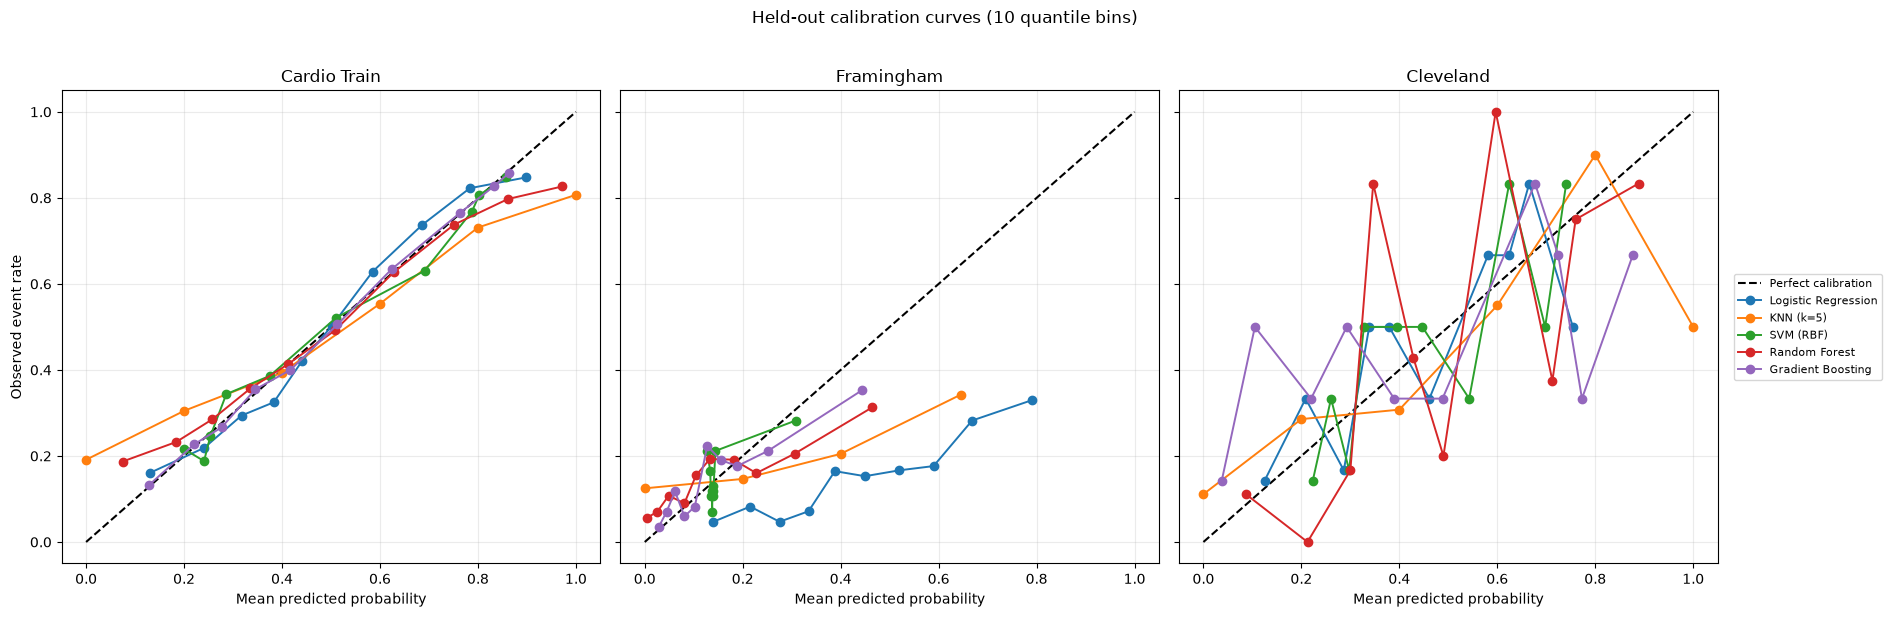

Saved C:\Users\kunug\OneDrive\Desktop\cardioVision\result\calibration_curves.png


In [3]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(19, 6), sharex=True, sharey=True)
for ax, dataset_name in zip(axes, DATASETS):
    y_test = data[f"{dataset_name}_y_test"]
    ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
    for model_name, probabilities in probabilities_by_dataset[dataset_name].items():
        observed, predicted = calibration_curve(
            y_test, probabilities, n_bins=10, strategy="quantile"
        )
        ax.plot(predicted, observed, marker="o", linewidth=1.4, label=model_name)
    ax.set_title(DISPLAY_NAMES[dataset_name])
    ax.set_xlabel("Mean predicted probability")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Observed event rate")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=8)
fig.suptitle("Held-out calibration curves (10 quantile bins)", y=1.02)
fig.tight_layout()
calibration_path = RESULT_DIR / "calibration_curves.png"
fig.savefig(calibration_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved {calibration_path}")

## Zero-shot cross-dataset evaluation

The five Cardio Train models above are trained once on the shared features. They are applied directly to held-out Framingham and Cleveland records using only the Cardio Train-fitted imputer and scaler—no destination retraining, refitting, or threshold adjustment. OOD ROC-AUC change is reported relative to each model's held-out Cardio Train ROC-AUC.

In [4]:
zero_shot_rows = []
for model_name, model in models_by_dataset["cardio_train"].items():
    cardio_auc = float(metrics.loc[
        (metrics["dataset"] == DISPLAY_NAMES["cardio_train"]) & (metrics["model"] == model_name),
        "roc_auc",
    ].iloc[0])
    for destination in ["framingham", "cleveland"]:
        X_ood = data[f"{destination}_ood_X_test"]
        y_ood = data[f"{destination}_ood_y_test"]
        scores = score_binary_model(model, X_ood, y_ood)
        scores.pop("probabilities")
        zero_shot_rows.append({
            "source": "Cardio Train",
            "destination": DISPLAY_NAMES[destination],
            "model": model_name,
            "cardio_test_roc_auc": cardio_auc,
            "ood_roc_auc": scores["roc_auc"],
            "roc_auc_change": scores["roc_auc"] - cardio_auc,
            **scores,
        })
        print(f"Zero-shot: {model_name} — {DISPLAY_NAMES[destination]}")

zero_shot = pd.DataFrame(zero_shot_rows)
display(zero_shot.round(4))

def markdown_table(frame, columns, float_format=".4f"):
    headers = "| " + " | ".join(columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    rows = []
    for _, row in frame[columns].iterrows():
        cells = []
        for column in columns:
            value = row[column]
            cells.append(format(value, float_format) if isinstance(value, (float, np.floating)) else str(value))
        rows.append("| " + " | ".join(cells) + " |")
    return "\n".join([headers, separator, *rows])

best_rows = metrics.loc[metrics.groupby("dataset")["roc_auc"].idxmax()]
summary_lines = [
    "# CardioVision modeling summary",
    "",
    "All metrics are computed on stratified held-out test sets. The 15 in-dataset fits use the six requested harmonized feature names; Logistic Regression is class-weighted only for Framingham. Precision, recall, and F1 use a 0.5 probability threshold. For runtime scalability, the RBF SVM uses a reproducible stratified 10,000-row subset of its training fold when that fold is larger; all other models use the full training fold, and every model is scored on the full test fold.",
    "",
    "## Dataset and class balance",
    "",
]
for dataset_name in DATASETS:
    y_train = data[f"{dataset_name}_y_train"]
    y_test = data[f"{dataset_name}_y_test"]
    summary_lines.append(
        f"- **{DISPLAY_NAMES[dataset_name]}:** {len(y_train) + len(y_test):,} records; "
        f"train/test = {len(y_train):,}/{len(y_test):,}; positive rate = "
        f"{y_train.mean():.1%}/{y_test.mean():.1%}."
    )
summary_lines.extend([
    "",
    "## In-dataset model comparison",
    "",
    markdown_table(metrics, ["dataset", "model", "accuracy", "precision", "recall", "f1", "roc_auc", "brier_score"]),
    "",
    "## Best ROC-AUC model per dataset",
    "",
    markdown_table(best_rows, ["dataset", "model", "roc_auc", "brier_score"]),
    "",
    "## Zero-shot Cardio Train → Framingham/Cleveland",
    "",
    "`roc_auc_change` = OOD ROC-AUC − held-out Cardio Train ROC-AUC (negative values indicate a drop). All destination records are evaluated without refitting the transferred model or its preprocessing.",
    "",
    markdown_table(zero_shot, ["destination", "model", "cardio_test_roc_auc", "ood_roc_auc", "roc_auc_change", "accuracy", "precision", "recall", "f1", "brier_score"]),
    "",
    "## Interpretation and limitations",
    "",
    "- Calibration curves are in `calibration_curves.png`; Brier scores in the tables measure probability error (lower is better).",
    "- The shared input columns are not measurement-equivalent: Cardio cholesterol/glucose are ordinal codes; Framingham cholesterol/glucose are measured concentrations; Cleveland uses cholesterol concentration and binary fasting blood sugar. Cardio sex codes were normalized to male=1, female=0.",
    "- Cleveland has no smoking field and only systolic resting pressure. Its requested shared `smoke` feature is filled using the Cardio Train training-fold median, and its shared `MAP` field uses systolic pressure as a clearly imperfect proxy. This mapping is fixed without fitting on Cleveland data.",
    "- The outcome definitions differ: Cardio disease status, Framingham ten-year CHD risk, and Cleveland disease presence. Zero-shot results confound population, measurement, and endpoint shifts and should not be interpreted as clinical performance estimates.",
    "",
])
summary_path = RESULT_DIR / "04_major_project_summary.md"
summary_path.write_text("\n".join(summary_lines), encoding="utf-8")
print(f"Wrote {summary_path}")
print("Best in-dataset ROC-AUC results:")
display(best_rows[["dataset", "model", "roc_auc", "brier_score"]].round(4))
print("Zero-shot ROC-AUC change range:", zero_shot["roc_auc_change"].min(), "to", zero_shot["roc_auc_change"].max())

Zero-shot: Logistic Regression — Framingham
Zero-shot: Logistic Regression — Cleveland
Zero-shot: KNN (k=5) — Framingham
Zero-shot: KNN (k=5) — Cleveland


Zero-shot: SVM (RBF) — Framingham
Zero-shot: SVM (RBF) — Cleveland
Zero-shot: Random Forest — Framingham
Zero-shot: Random Forest — Cleveland
Zero-shot: Gradient Boosting — Framingham
Zero-shot: Gradient Boosting — Cleveland


,source,destination,model,cardio_test_roc_auc,ood_roc_auc,roc_auc_change,accuracy,precision,recall,f1,roc_auc,brier_score
0,Cardio Train,Framingham,Logistic Regression,0.7755,0.5045,-0.2710,0.1592,0.1532,1.0000,0.2657,0.5045,0.8391
1,Cardio Train,Cleveland,Logistic Regression,0.7755,0.5000,-0.2755,0.4590,0.4590,1.0000,0.6292,0.5000,0.5410
2,Cardio Train,Framingham,KNN (k=5),0.7356,0.5824,-0.1532,0.3892,0.1742,0.8062,0.2865,0.5824,0.4205
3,Cardio Train,Cleveland,KNN (k=5),0.7356,0.5395,-0.1961,0.4426,0.4483,0.9286,0.6047,0.5395,0.3600
4,Cardio Train,Framingham,SVM (RBF),0.7748,0.5039,-0.2710,0.1568,0.1528,1.0000,0.2652,0.5039,0.3929
5,Cardio Train,Cleveland,SVM (RBF),0.7748,0.5000,-0.2748,0.4590,0.4590,1.0000,0.6292,0.5000,0.2913
6,Cardio Train,Framingham,Random Forest,0.7595,0.5875,-0.1720,0.4186,0.1773,0.7752,0.2886,0.5875,0.3964
7,Cardio Train,Cleveland,Random Forest,0.7595,0.4394,-0.3201,0.4590,0.4545,0.8929,0.6024,0.4394,0.4143
8,Cardio Train,Framingham,Gradient Boosting,0.7876,0.6331,-0.1545,0.3962,0.1814,0.8450,0.2986,0.6331,0.3601
9,Cardio Train,Cleveland,Gradient Boosting,0.7876,0.5065,-0.2811,0.4590,0.4590,1.0000,0.6292,0.5065,0.4101


Wrote C:\Users\kunug\OneDrive\Desktop\cardioVision\result\04_major_project_summary.md
Best in-dataset ROC-AUC results:


,dataset,model,roc_auc,brier_score
4,Cardio Train,Gradient Boosting,0.7876,0.1868
11,Cleveland,KNN (k=5),0.7603,0.2026
5,Framingham,Logistic Regression,0.6908,0.2148


Zero-shot ROC-AUC change range: -0.32007531198197925 to -0.15319722595863483
